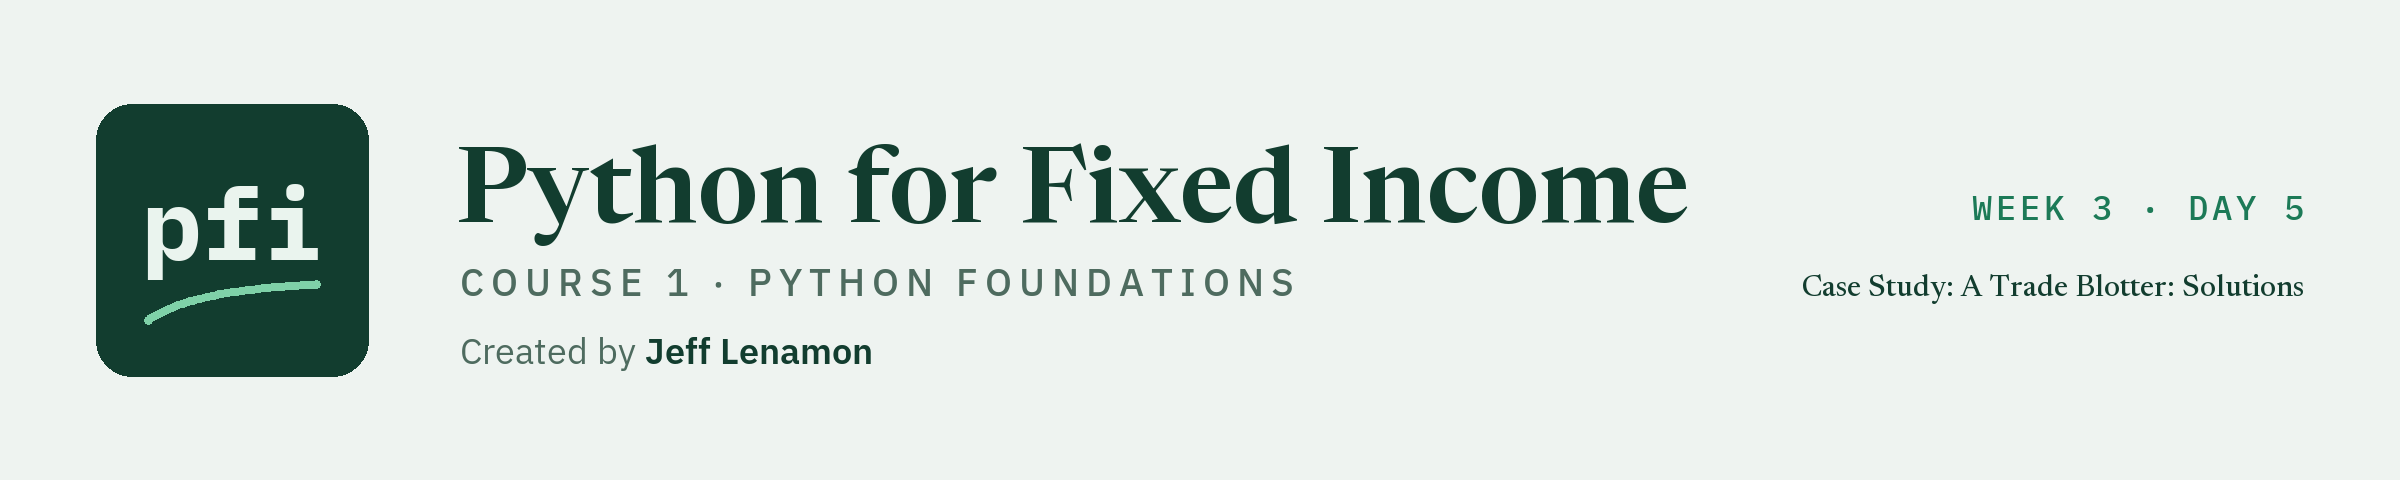

# Case Study: A Trade Blotter: Solutions

Week 3, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day5/15_case_study_trade_blotter_solutions.ipynb)

## Exercises

These are the worked answers; every name in the blotter is invented.
Run the next two cells first: the first defines `check`; the second loads the files and the joined table.

In [1]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [2]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house theme, the three files, and the lesson's joined table
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
if os.path.exists('../../../data/trade_blotter.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
blotter = pd.read_csv(data_folder + 'trade_blotter.csv', parse_dates=['trade_date', 'settle_date'])
holdings = pd.read_csv(data_folder + 'holdings.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
bond_details = holdings[['cusip', 'issuer', 'sector', 'rating', 'price', 'market_value']]
bond_details = bond_details.rename(columns={'price': 'month_end_price'})
trades = pd.merge(blotter, bond_details, on='cusip', how='left', validate='many_to_one')
trades = pd.merge(trades, ratings[['rating', 'grade']], on='rating', how='left',
                  validate='many_to_one')
print(blotter.shape, trades.shape)

(374, 12) (374, 18)


### Exercise 1

Q. Apply the IQR rule to `principal`: store the number of trades above the upper limit in **ex1_flagged** and the largest principal in **ex1_largest**. Are they errors?

In [3]:
q1, q3 = blotter['principal'].quantile(0.25), blotter['principal'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
flagged = blotter[blotter['principal'] > upper_limit]
ex1_flagged = len(flagged)
ex1_largest = flagged['principal'].max()
print('limit:', upper_limit, '| flagged:', ex1_flagged, '| largest:', ex1_largest)
flagged[['trade_id', 'ticker', 'side', 'quantity', 'price', 'principal']].sort_values('principal',
                                                                                  ascending=False)

limit: 823855.125 | flagged: 10 | largest: 5335100.0


,trade_id,ticker,side,quantity,price,principal
159,T0160,CLAE,SELL,5000000,106.702,5335100.0
50,T0051,RULL,SELL,4000000,103.059,4122360.0
236,T0237,PLER,BUY,3000000,98.307,2949210.0
366,T0367,VRAN,SELL,3000000,92.203,2766090.0
150,T0151,DRAH,BUY,2500000,94.101,2352525.0
137,T0138,THAN,SELL,2000000,94.181,1883620.0
118,T0119,GRON,BUY,750000,116.857,876427.5
187,T0188,SKEY,BUY,750000,116.080,870600.0
190,T0191,HESR,BUY,750000,113.677,852577.5
331,T0332,VYRE,BUY,760000,109.973,835794.8


The limit is 823,855.125 dollars of principal: ten trades are past it, the six large quantities and four trades of 750,000 to 760,000 face priced from 109.973 to 116.857.
Principal mixes size and price, so a high price lifts a mid-size trade over the line.
None is an error: every principal tied to quantity x price / 100 in the lesson.

In [4]:
check('Exercise 1 trades flagged', ex1_flagged, 10)
check('Exercise 1 largest principal', ex1_largest, 5335100.0)

Exercise 1 trades flagged: correct
Exercise 1 largest principal: correct


### Exercise 2

Q. Add up the principal by hour, in millions. Store the hour with the most in **ex2_hour** and its principal, to 2 places, in **ex2_millions**. Draw principal by hour as bars.

In [5]:
# the hour, as in the lesson: text read as a time, then .dt.hour
blotter['hour'] = pd.to_datetime(blotter['trade_time'], format='%H:%M').dt.hour
by_hour = blotter.groupby('hour')['principal'].sum() / 1_000_000
ex2_hour = by_hour.idxmax()
ex2_millions = round(by_hour.max(), 2)
print(ex2_hour, ex2_millions)
print(by_hour.round(2).to_dict())

11 21.29
{8: 5.51, 9: 18.38, 10: 20.44, 11: 21.29, 12: 5.54, 13: 5.14, 14: 20.5, 15: 9.69, 16: 10.98}


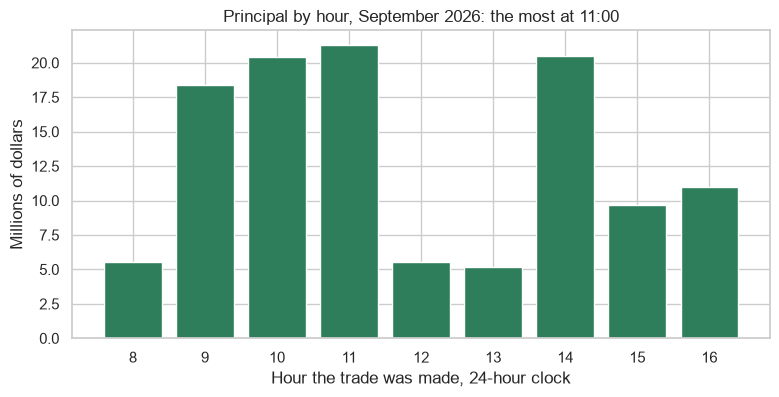

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour.values)
ax.set_xticks(by_hour.index)
ax.set_title('Principal by hour, September 2026: the most at 11:00')
ax.set_xlabel('Hour the trade was made, 24-hour clock')
ax.set_ylabel('Millions of dollars')
plt.show()

11:00 carries the most dollars, 21.29 million, though 10:00 had the most trades, 67.
14:00 nearly matches it at 20.50 million: count and dollars rank the hours differently.

In [7]:
check('Exercise 2 hour', ex2_hour, 11)
check('Exercise 2 millions', ex2_millions, 21.29)

Exercise 2 hour: correct
Exercise 2 millions: correct


### Exercise 3

Q. Work out the net principal by grade, in millions to 2 places, in **ex3_ig** and **ex3_hy**; check they add to the blotter's net, and draw them with a zero line.

In [8]:
by_grade = pd.pivot_table(trades, values='principal', index='grade', columns='side',
                          aggfunc='sum') / 1_000_000
by_grade['net'] = by_grade['BUY'] - by_grade['SELL']
ex3_ig = round(by_grade.loc['Investment Grade', 'net'], 2)
ex3_hy = round(by_grade.loc['High Yield', 'net'], 2)
print(ex3_ig, ex3_hy, '| the two add to:', round(by_grade['net'].sum(), 2))
by_grade.round(2)

-8.63 4.27 | the two add to: -4.36


side,BUY,SELL,net
grade,,,
High Yield,14.22,9.96,4.27
Investment Grade,42.33,50.96,-8.63


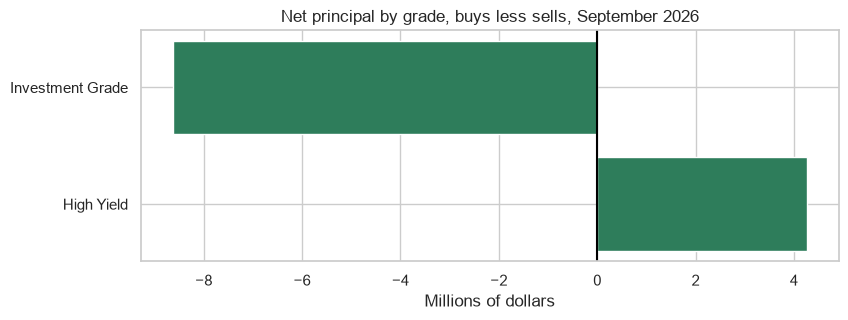

In [9]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(by_grade.index, by_grade['net'])
ax.axvline(0, color='black')
ax.set_title('Net principal by grade, buys less sells, September 2026')
ax.set_xlabel('Millions of dollars')
plt.show()

Investment Grade net sold 8.63 million and High Yield net bought 4.27; the two add to the blotter's -4.36.
Both of Investment Grade's sides are the larger, 42.33 bought and 50.96 sold: it has more trades, and every large one.

In [10]:
check('Exercise 3 Investment Grade net', ex3_ig, -8.63)
check('Exercise 3 High Yield net', ex3_hy, 4.27)

Exercise 3 Investment Grade net: correct
Exercise 3 High Yield net: correct


### Exercise 4

Q. Which bond traded second most often? Store its cusip in **ex4_cusip** and its simple and volume-weighted average prices, to 3 places, in **ex4_simple** and **ex4_weighted**.

In [11]:
# value_counts() puts the most traded first, so the second is at position 1
ex4_cusip = trades['cusip'].value_counts().index[1]
bond = trades[trades['cusip'] == ex4_cusip]
ex4_simple = round(bond['price'].mean(), 3)
ex4_weighted = round((bond['price'] * bond['quantity']).sum() / bond['quantity'].sum(), 3)
print(ex4_cusip, bond['ticker'].iloc[0], len(bond), 'trades')
print('simple:', ex4_simple, '| weighted:', ex4_weighted,
      '| month end:', bond['month_end_price'].iloc[0])

99114KAB6 LORE 16 trades
simple: 104.706 | weighted: 104.687 | month end: 105.239


`99114KAB6`, LORE, traded 16 times: simple 104.706, weighted 104.687, both under its month-end 105.239.
As with CORA, the weighted average is the lower: more face traded at the lower prices.

In [12]:
check('Exercise 4 cusip', ex4_cusip, '99114KAB6')
check('Exercise 4 simple average', ex4_simple, 104.706)
check('Exercise 4 weighted average', ex4_weighted, 104.687)

Exercise 4 cusip: correct
Exercise 4 simple average: correct
Exercise 4 weighted average: correct


### Exercise 5

Q. Complete **weighted_average_price**: given trades and a cusip, return the volume-weighted average traded price to 3 places, and stop with an `assert` and a message when the cusip has no trades.

In [13]:
def weighted_average_price(table, cusip):
    bond = table[table['cusip'] == cusip]
    # stop with a message, not a division by zero, when the bond has no trades
    assert len(bond) > 0, 'no trades in ' + cusip
    return round((bond['price'] * bond['quantity']).sum() / bond['quantity'].sum(), 3)


ex5_first = weighted_average_price(trades, '99075XAE9')
ex5_second = weighted_average_price(trades, '99114KAB6')
print(ex5_first, ex5_second)

99.742 104.687


Both match the lesson and Exercise 4: one function, any bond.
The `assert` stops a cusip with no trades, with a message, before any division.

In [14]:
if ex5_first is ... or ex5_first is None:
    check('Exercise 5', ex5_first, 99.742)
else:
    check('Exercise 5 99075XAE9', ex5_first, 99.742)
    check('Exercise 5 99114KAB6', ex5_second, 104.687)
    # a cusip with no trades should stop the function; try and except, week 1's Day 3, catch it
    try:
        weighted_average_price(trades, 'NOTACUSIP')
        stopped = False
    except AssertionError as error:
        stopped = True
        print('Stopped with:', error)
    check('Exercise 5 the assert stops a cusip with no trades', stopped, True)

Exercise 5 99075XAE9: correct
Exercise 5 99114KAB6: correct
Stopped with: no trades in NOTACUSIP
Exercise 5 the assert stops a cusip with no trades: correct


### Exercise 6

Q. Group the lesson's `daily` net into weeks ending Friday with `resample('W-FRI')`, as in the Treasury case study. Store the Friday of the most net selling, as text like `'2026-09-04'`, in **ex6_week** and its net in millions, to 2 places, in **ex6_net**. Draw the weekly nets with a zero line.

In [15]:
# the lesson's daily table, one row per trade date
daily = pd.pivot_table(trades, values='principal', index='trade_date', columns='side',
                       aggfunc='sum', fill_value=0) / 1_000_000
daily['net'] = daily['BUY'] - daily['SELL']
# 'W-FRI': weeks that end on a Friday, each labelled by its Friday
weekly = daily['net'].resample('W-FRI').sum()
ex6_week = weekly.idxmin().strftime('%Y-%m-%d')
ex6_net = round(weekly.min(), 2)
print(weekly.round(2))
print(ex6_week, ex6_net, '| the weeks add to:', round(weekly.sum(), 2))

trade_date
2026-09-04   -3.11
2026-09-11   -9.48
2026-09-18    1.65
2026-09-25    5.38
2026-10-02    1.20
Freq: W-FRI, Name: net, dtype: float64
2026-09-11 -9.48 | the weeks add to: -4.36


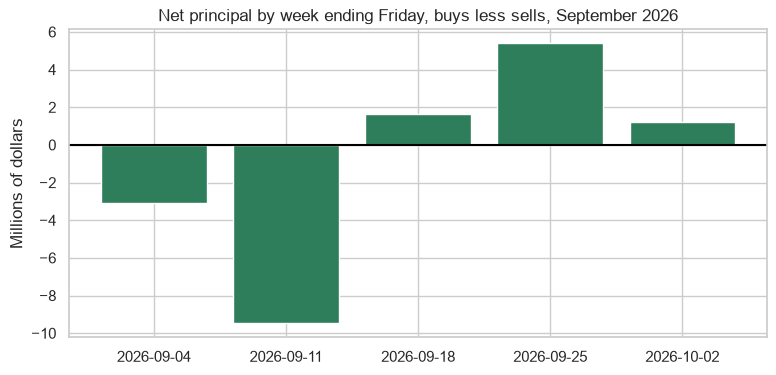

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekly.index.strftime('%Y-%m-%d'), weekly.values)
ax.axhline(0, color='black')
ax.set_title('Net principal by week ending Friday, buys less sells, September 2026')
ax.set_ylabel('Millions of dollars')
plt.show()

Five weeks, -3.11, -9.48, 1.65, 5.38, and 1.20, which add to -4.36; the last, to 2026-10-02, holds only three trading days.
The week ending 2026-09-11 net sold the most, 9.48 million; it starts on Tuesday 2026-09-08, after the holiday, so it has four trading days, as the first week does.

In [17]:
check('Exercise 6 week', ex6_week, '2026-09-11')
check('Exercise 6 net', ex6_net, -9.48)

Exercise 6 week: correct
Exercise 6 net: correct


### Exercise 7: AI check

Q. From the lesson's tables, what should Financials and the whole blotter show? Find the bug and fix the cell.

The lesson's tables give the right answers: Financials -7.04 and the whole blotter -4.36.
The AI's code adds `principal` with no sign, so every sell counts as a buy: its 16.13 is Financials' total traded and its 117.47 the blotter's.
It runs, and the numbers look like money: only the lesson's net-and-total check catches it.
The fix: make the sells negative, then add.

In [18]:
# a signed copy of principal: buys as they are, sells below zero
trades['signed'] = trades['principal']
trades.loc[trades['side'] == 'SELL', 'signed'] = -trades['principal']
net_by_sector = trades.groupby('sector')['signed'].sum() / 1_000_000
ex7_financials = round(net_by_sector.loc['Financials'], 2)
ex7_total = round(net_by_sector.sum(), 2)
print('Net bought, Financials:', ex7_financials, '| whole blotter:', ex7_total, 'million dollars')

Net bought, Financials: -7.04 | whole blotter: -4.36 million dollars


In [19]:
check('Exercise 7 Financials net', ex7_financials, -7.04)
check('Exercise 7 whole blotter net', ex7_total, -4.36)

Exercise 7 Financials net: correct
Exercise 7 whole blotter net: correct
